In [104]:
import pandas as pd 
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [105]:
df = pd.read_csv('cleaned_data.csv')

In [106]:
df = df.drop(columns = 'Unnamed: 0')

In [107]:
df.head()

,type,air_temp_c,rotational_speed_[rpm],torque_[nm],tool_wear_[min],target,temp_diff_c,power,strain
0,M,24.95,1551,42.8,0,0,10.5,6951.590560,0.0
1,L,25.05,1408,46.3,3,0,10.5,6826.722724,138.9
2,L,24.95,1498,49.4,5,0,10.4,7749.387543,247.0
3,L,25.05,1433,39.5,7,0,10.4,5927.504659,276.5
4,L,25.05,1408,40.0,9,0,10.5,5897.816608,360.0


Create train test split.

In [108]:
from sklearn.model_selection import train_test_split

In [109]:
X = df.drop(columns = 'target')
y = df['target']

In [110]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2)

Filter methods for feature selection 
- Spearman correlation coeffcient for relationship between features and target

In [111]:
train = pd.concat([X_train, y_train], axis = 1)

In [112]:
corr_matrix = train.corr(method = 'spearman', numeric_only = True)

In [113]:
mask = np.triu(np.ones_like(corr_matrix, dtype = bool))

<Axes: >

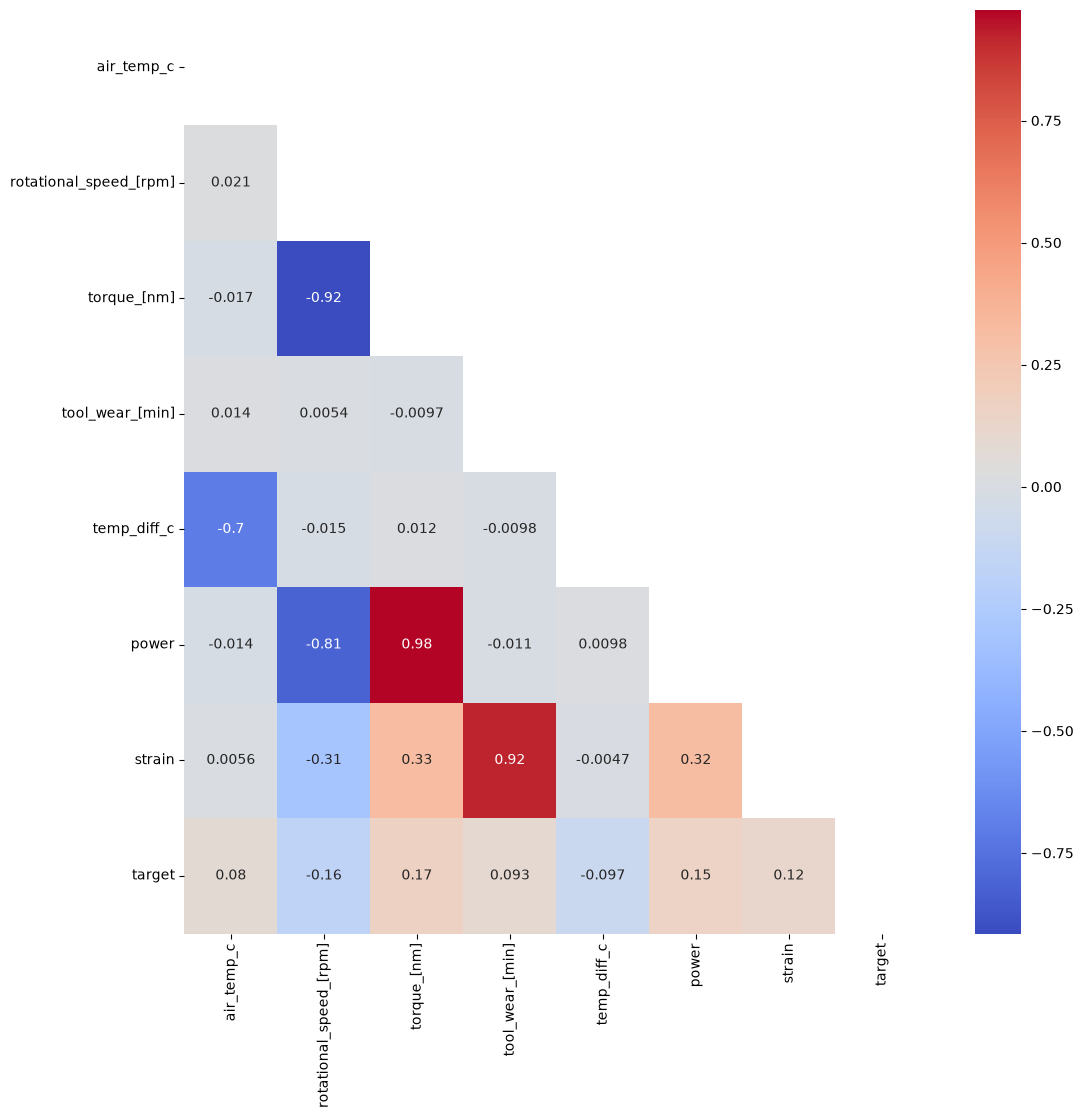

In [114]:
plt.figure(figsize = (12,12))
sns.heatmap(data = corr_matrix, mask = mask, annot = True,
           cmap = 'coolwarm')

No one individual feature seems to have high correlation to target. Mutual information shows that certain combinations of features is correlated to higher risk of failure (as seen by EDA). E.g. higher rpm low torque or vice versa. 

Now moving on. This is a classification task. Build a baseline and two models. 

Two solid choices would be
- Logistic regression (with/without regularisation)
    - May struggle to pick up U-shaped patterns unless we build these in. Try and build in some of finding from EDA. 
- RandomForest/GradientBoostedTrees
  - Less interperable, not as useful for client. Need to use SHAP/LIME to get feature importance.
 
Tune both models, then compare best models, against each other and baseline. 

Use best model to get model based feature importance. Report best model test-set performance and feature importance findings. 

This is synthetic data so won't be extreme outliers, use StandardScaler. 

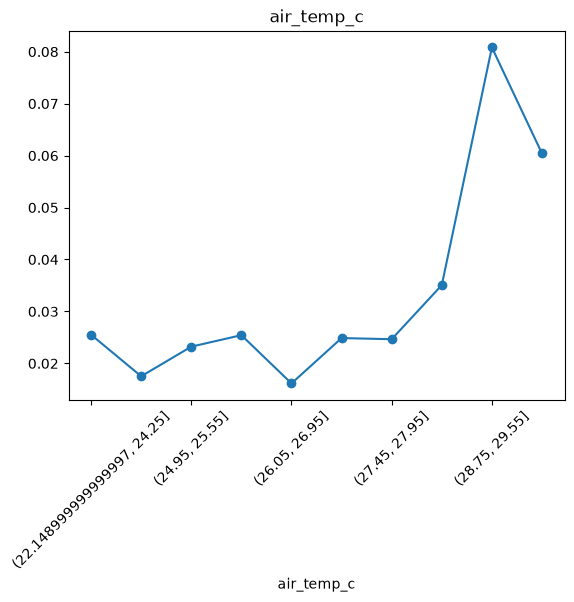

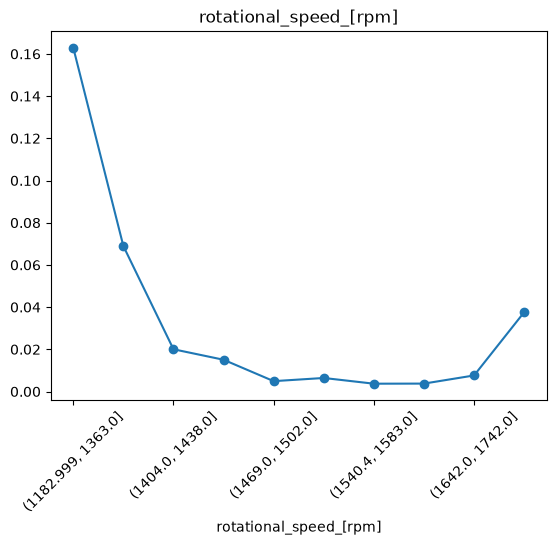

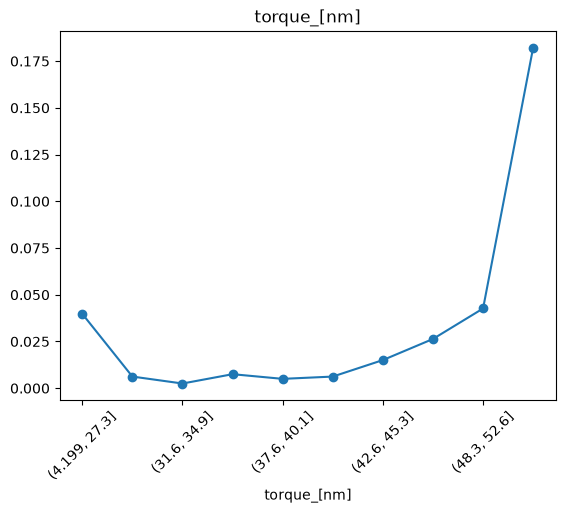

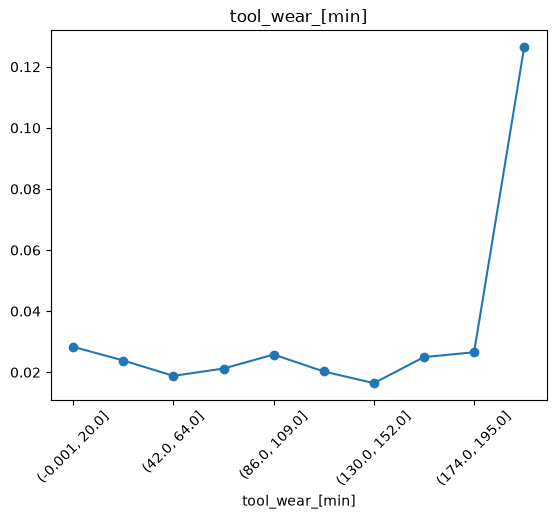

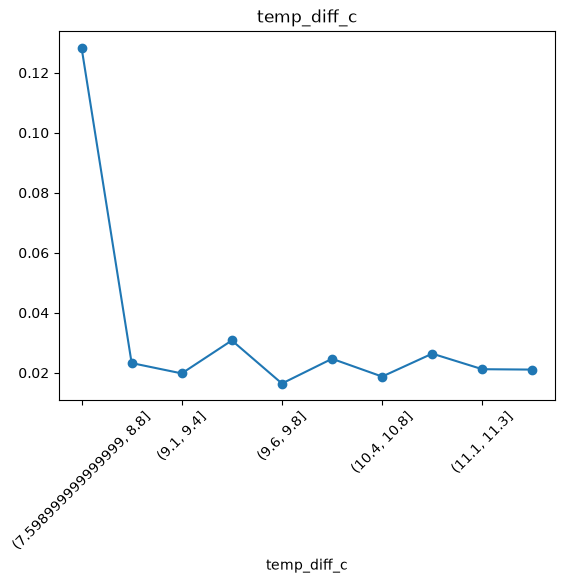

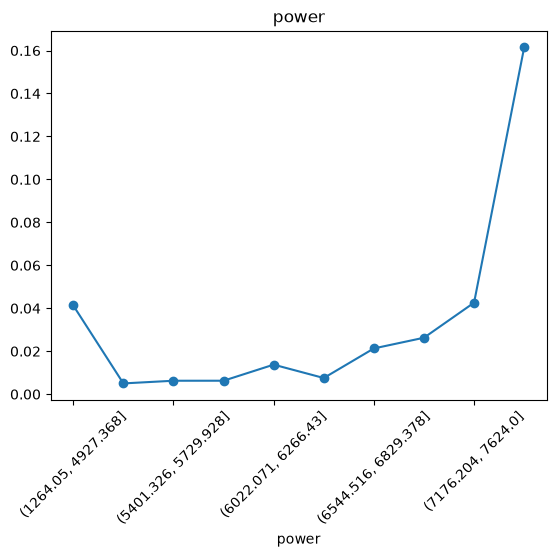

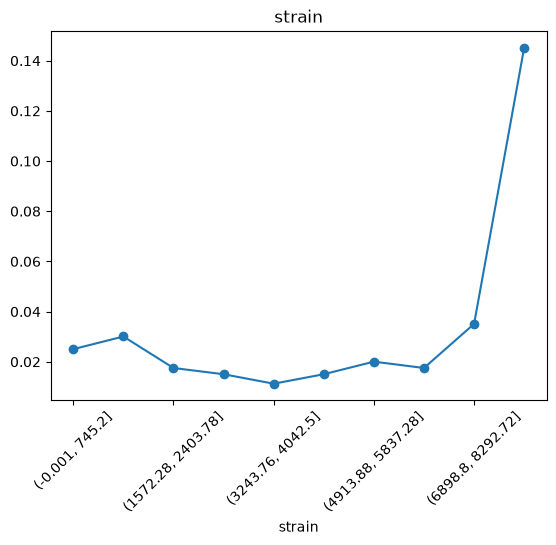

In [115]:
for col in X_train.select_dtypes(include = 'number').columns: 
    failures = y_train.groupby(pd.qcut(X_train[col], 10)).mean()
    failures.plot(marker = 'o', title = col, rot = 45)
    plt.show()

- Jump in failure rate for high power, torque, tool wear, strain.
- Jump in failure rate for low temp diff and rotational speed
- We know there to be interactions between these features too. High torque lower power = failure, High power, low torque = failure. 

In [182]:
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import PrecisionRecallDisplay, ConfusionMatrixDisplay, confusion_matrix

In [183]:
def make_pre(): 
    return ColumnTransformer([
    ('type', Pipeline([('enc', OrdinalEncoder(categories = [['L', 'M', 'H']])), 
                       ('sc', StandardScaler())]), ['type']), 
    ('num', StandardScaler(), make_column_selector(dtype_include='number')),
], remainder='drop').set_output(transform = 'pandas')
                                                         

In [155]:
dummy = Pipeline([('pre', make_pre()), 
                  ('model', DummyClassifier(strategy='stratified',random_state=42))])

In [156]:
cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

In [157]:
pd.DataFrame(cross_validate(dummy, X_train, y_train, cv = cv, scoring = 'average_precision',
                           return_train_score = True)).aggregate(['mean', 'std'])

,fit_time,score_time,test_score,train_score
mean,0.005262,0.002709,0.033321,0.033536
std,0.002568,0.000562,0.000595,0.000340


This is expected. For PR curve for random classifier, we flag approx 3.4% of cases at random as failures. Precision is amount of flagged machines which actually fail, this is 3.4%. Recall is whatever the threshold is for the model, t. So line is horizontal fixed at 3.4 approx. 

In [158]:
lr_base = Pipeline([('pre', pre), ('model', LogisticRegression(l1_ratio = 1, solver='liblinear'))])

In [159]:
lr_base.fit(X_train, y_train)
names = lr_base.named_steps['pre'].get_feature_names_out()
coefs = pd.Series(lr_base.named_steps['model'].coef_[0], index=names)
coefs.sort_values()

num__power                    -2.864634
num__temp_diff_c              -0.710684
type__type                    -0.222837
num__strain                    0.000000
num__air_temp_c                0.066447
num__tool_wear_[min]           0.855018
num__rotational_speed_[rpm]    2.287864
num__torque_[nm]               5.831909
dtype: float64

- Collinearity in torque, power, rpm as power = torque * rpm, drop rpm and torque and leave interaction as that's what is important
- Squaring power term may be worthwhile. 

In [160]:
pd.DataFrame(cross_validate(lr_base, X_train, y_train, cv = cv, 
               scoring = ['average_precision', 'precision', 'recall'], return_train_score = True)).aggregate(['mean', 'std']).T

,mean,std
fit_time,0.056731,0.013391
score_time,0.004311,0.000647
test_average_precision,0.492790,0.107312
train_average_precision,0.487681,0.029978
test_precision,0.738653,0.208957
train_precision,0.721898,0.043837
test_recall,0.241509,0.069837
train_recall,0.256604,0.035393


In [161]:
lr_base_preds = cross_val_predict(lr_base, X_train, y_train, cv=cv)
lr_base_proba = cross_val_predict(lr_base, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

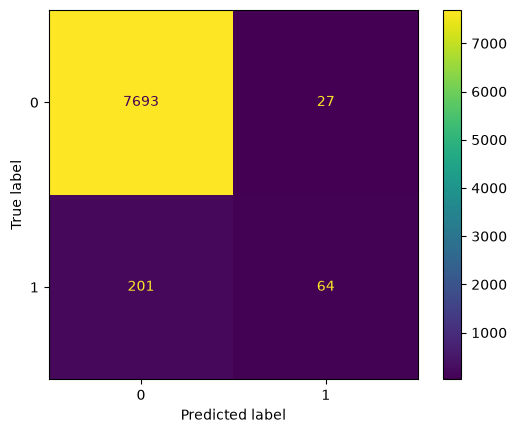

In [162]:
cm = confusion_matrix(y_train, lr_base_preds)
ConfusionMatrixDisplay(cm).plot()

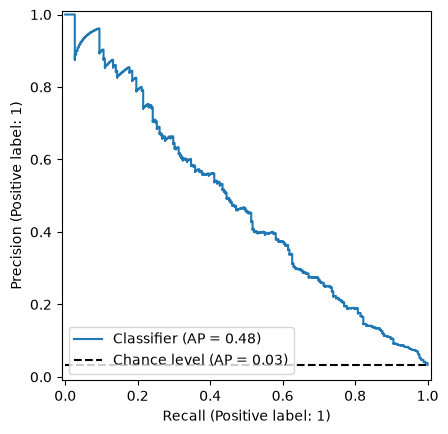

In [163]:
PrecisionRecallDisplay.from_predictions(y_train, lr_base_proba, plot_chance_level=True)
plt.show()

- Good PR-AUC, better than stratified dummy classifier.
- Using 0.5 base threshold. Approx 74% precision but low recall. Out of all positive predictions we have a good chance of predicting failure, so we only have false positives a quarter of the time. However, we miss a large number of true positives. 

In [195]:
def drop_cols(X): 
    return X.drop(columns = ['torque_[nm]', 'rotational_speed_[rpm]'])

lr_a = Pipeline([('drop', FunctionTransformer(drop_cols)), 
                ('pre', make_pre()), 
                ('model', LogisticRegression(l1_ratio = 1, solver = 'liblinear')),              
])

In [196]:
def add_power(X): 
    X = X.copy()
    X['power_sq'] = X['num__power'] ** 2 
    return X 

In [197]:
lr_b = Pipeline([
    ('pre',   make_pre()),
    ('sq',    FunctionTransformer(add_power)),
    ('model', LogisticRegression(l1_ratio = 1, solver = 'liblinear')),
])

In [198]:
pd.DataFrame(cross_validate(lr_a, X_train, y_train, cv = cv, 
               scoring = ['average_precision', 'precision', 'recall'], return_train_score = True)).aggregate(['mean', 'std']).T

,mean,std
fit_time,0.025876,0.005460
score_time,0.005965,0.001239
test_average_precision,0.373871,0.079491
train_average_precision,0.378874,0.020841
test_precision,1.000000,0.000000
train_precision,0.969424,0.046565
test_recall,0.056604,0.013342
train_recall,0.066038,0.025182


In [199]:
pd.DataFrame(cross_validate(lr_b, X_train, y_train, cv = cv, 
               scoring = ['average_precision', 'precision', 'recall'], return_train_score = True)).aggregate(['mean', 'std']).T

,mean,std
fit_time,0.075267,0.016109
score_time,0.005545,0.000663
test_average_precision,0.521429,0.096069
train_average_precision,0.522670,0.025627
test_precision,0.724012,0.192187
train_precision,0.702395,0.013385
test_recall,0.298113,0.048838
train_recall,0.297170,0.029268


Dropping the features hurt PR-AUC by approx 12%. Adding power squared helped improve PR-AUC by 3%. Lets tune lr_b to see if we can tweak the probability threshold to get the best probability threshold. 

Let's assume the client said that the cost of a false positive (sending team out) is $200, and cost of missing failure (missed 1-2 days of production), cost 2000 dollars in profit. So c_FP = 1 and c_FN = 10. 

In [204]:
lr_b_proba = cross_val_predict(lr_b, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

def best_thresh(y_true, proba, c_fn = 2000, c_fp = 200): 
    thresholds = np.linspace(0,1, 201)
    
    lowest_cost = np.inf 
    best_t = None         
    
    for t in thresholds: 
        n_fp = ((proba >= t) & (y_true == 0)).sum()
        n_fn = ((proba < t) & (y_true == 1)).sum()
    
        cost = n_fp * c_fp + n_fn * c_fn
        if cost < lowest_cost: 
            lowest_cost = cost
            best_t = t 
            
    return best_t, lowest_cost

In [205]:
t, cost = best_thresh(y_train, lr_b_proba)

In [206]:
print(t, cost)

0.125 247600


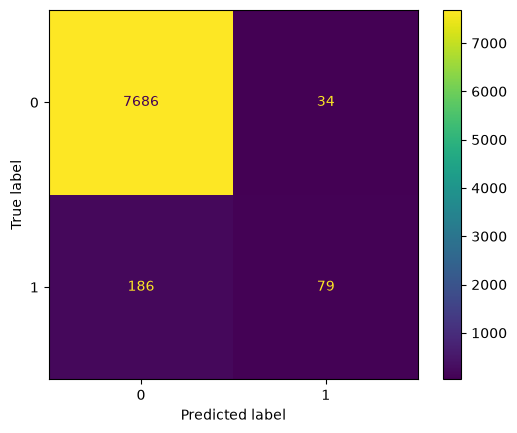

In [207]:
lr_b_pred = cross_val_predict(lr_b, X_train, y_train, cv=cv)

cm = confusion_matrix(y_train, lr_b_pred)
ConfusionMatrixDisplay(cm).plot()

Final logistic regression model catches 79 out of 265 failures. Total cost is 247,600. Compared to 265 * 2000 = 5.3 million. 

A random forest averages many deep trees, each trained on a bootstrap sample with random features at every split. That reduces variance. Gradient boosting adds shallow trees in sequence, each fitting the remaining errors and scaled down by the learning rate. That reduces bias. Boosting usually wins on tabular data but needs tuning. A forest is safer when the data is small or noisy. We will try both methods out of the box, choose the best out of box, and tune it. 

In [209]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier 

In [212]:
def make_pre_1(): 
    return ColumnTransformer([('ord', OrdinalEncoder(categories = [['L', 'M', 'H']]), ['type']
                              )], remainder = 'passthrough').set_output(transform = 'pandas')

rf_base = Pipeline([('pre', make_pre_1()), ('model', RandomForestClassifier(random_state = 42, n_jobs = -1))])
gbt_base = Pipeline([('pre', make_pre_1()), ('model', HistGradientBoostingClassifier(random_state = 42))])

In [215]:
pd.DataFrame(cross_validate(rf_base, X_train, y_train, cv = cv, scoring = ['average_precision', 'recall', 'precision'], n_jobs = -1, 
                           return_train_score = True)).aggregate(['mean', 'std']).T

,mean,std
fit_time,0.166647,2.979354e-02
score_time,0.032765,1.917820e-03
test_average_precision,0.889146,4.176239e-02
train_average_precision,1.000000,1.241267e-16
test_recall,0.800000,3.427529e-02
train_recall,1.000000,0.000000e+00
test_precision,0.963599,2.067584e-02
train_precision,1.000000,0.000000e+00


In [247]:
pd.DataFrame(cross_validate(rf_base, X_train, y_train, cv = cv, scoring = ['average_precision', 'recall', 'precision'], n_jobs = -1, 
                           return_train_score = True)).T

,0,1,2,3,4
fit_time,0.240125,0.248873,0.248540,0.245198,0.240711
score_time,0.035890,0.043078,0.034222,0.031859,0.031142
test_average_precision,0.908813,0.850635,0.911061,0.839541,0.935682
train_average_precision,1.000000,1.000000,1.000000,1.000000,1.000000
test_recall,0.830189,0.773585,0.811321,0.754717,0.830189
train_recall,1.000000,1.000000,1.000000,1.000000,1.000000
test_precision,0.977778,0.976190,0.977273,0.930233,0.956522
train_precision,1.000000,1.000000,1.000000,1.000000,1.000000


In [216]:
pd.DataFrame(cross_validate(gbt_base, X_train, y_train, cv = cv, scoring = ['average_precision', 'recall', 'precision'], n_jobs = -1, 
                           return_train_score = True)).aggregate(['mean', 'std']).T

,mean,std
fit_time,0.097424,1.045913e-02
score_time,0.023300,2.956377e-03
test_average_precision,0.872218,2.370677e-02
train_average_precision,1.000000,1.241267e-16
test_recall,0.784906,6.342542e-02
train_recall,1.000000,0.000000e+00
test_precision,0.941824,4.432305e-02
train_precision,1.000000,0.000000e+00


In [246]:
pd.DataFrame(cross_validate(gbt_base, X_train, y_train, cv = cv, scoring = ['average_precision', 'recall', 'precision'], n_jobs = -1, 
                           return_train_score = True)).T

,0,1,2,3,4
fit_time,0.113091,0.116222,0.114678,0.107660,0.114921
score_time,0.025172,0.022534,0.026101,0.024903,0.023557
test_average_precision,0.877556,0.856946,0.910937,0.851787,0.863866
train_average_precision,1.000000,1.000000,1.000000,1.000000,1.000000
test_recall,0.811321,0.792453,0.867925,0.754717,0.698113
train_recall,1.000000,1.000000,1.000000,1.000000,1.000000
test_precision,0.914894,0.893617,1.000000,0.975610,0.925000
train_precision,1.000000,1.000000,1.000000,1.000000,1.000000


In [218]:
from sklearn.model_selection import RandomizedSearchCV

In [223]:
gbt_tune = Pipeline([('pre', make_pre_1()), ('model', HistGradientBoostingClassifier(random_state=42, early_stopping=True))])

In [224]:
from scipy.stats import loguniform, randint

In [235]:
param_dist = {
    'model__learning_rate': loguniform(0.01, 0.2),
    'model__max_leaf_nodes': randint(8, 32),
    'model__min_samples_leaf': randint(5, 50),
    'model__class_weight': [None, 'balanced'],
}

In [236]:
r_search = RandomizedSearchCV(gbt_tune, param_distributions=param_dist, n_iter = 20, cv = cv, scoring = 'average_precision', return_train_score=True, 
                  random_state = 42, n_jobs = -1)

In [237]:
r_search.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__class_weight': [None, 'balanced'], 'model__learning_rate': <scipy.stats....t 0x140548180>, 'model__max_leaf_nodes': <scipy.stats....t 0x136a969c0>, 'model__min_samples_leaf': <scipy.stats....t 0x136a96be0>}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For

In [238]:
r_search.best_params_

{'model__class_weight': None,
 'model__learning_rate': np.float64(0.0774366101159884),
 'model__max_leaf_nodes': 19,
 'model__min_samples_leaf': 12}

In [239]:
r_search.best_score_

np.float64(0.8804668505250346)

In [241]:
gbt_best = r_search.best_estimator_

In [244]:
pd.DataFrame(cross_validate(gbt_best, X_train, y_train, cv =cv, n_jobs = -1, return_train_score=True, scoring = ['average_precision', 'recall', 'precision'])).aggregate(['mean','std']).T

,mean,std
fit_time,0.055200,0.005865
score_time,0.012613,0.003381
test_average_precision,0.880467,0.026904
train_average_precision,0.985735,0.006402
test_recall,0.769811,0.027986
train_recall,0.930189,0.035830
test_precision,0.916425,0.030743
train_precision,0.984874,0.012090


In [248]:
pd.DataFrame(cross_validate(gbt_best, X_train, y_train, cv =cv, n_jobs = -1, return_train_score=True, scoring = ['average_precision', 'recall', 'precision'])).T

,0,1,2,3,4
fit_time,0.051993,0.052833,0.053355,0.056846,0.063996
score_time,0.011278,0.010944,0.017166,0.015868,0.015654
test_average_precision,0.903219,0.849768,0.909879,0.856700,0.882769
train_average_precision,0.981508,0.983543,0.978719,0.993401,0.991505
test_recall,0.811321,0.773585,0.773585,0.754717,0.735849
train_recall,0.900943,0.943396,0.891509,0.981132,0.933962
test_precision,0.877551,0.891304,0.931818,0.930233,0.951220
train_precision,0.984536,0.990099,0.964286,0.990476,0.994975


A very basic tuning of GBT produces no better results then RFs. We will stick with base RFs. 

In [249]:
final_model = rf_base

In [254]:
final_predict = cross_val_predict(rf_base, X_train, y_train, cv=cv, method = 'predict_proba')[:,1]

In [255]:
best_t, best_score = best_thresh(y_train, final_predict)

In [256]:
print(best_t, best_score)

0.28500000000000003 86000


Cost is $86,000, a lot lower than logistic regression!

In [257]:
final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['type','air_temp_c','rotational_speed_[rpm]',...,'temp_diff_c','power', 'strain']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('ord', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining colu

In [258]:
test_proba = final_model.predict_proba(X_test)[:,1]
test_pred = test_proba >= best_t 

In [261]:
from sklearn.metrics import average_precision_score, classification_report

In [260]:
average_precision_score(y_test, test_proba)

0.8988258364612806

In [264]:
print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      1.00      1923
           1       0.89      0.86      0.88        74

    accuracy                           0.99      1997
   macro avg       0.94      0.93      0.94      1997
weighted avg       0.99      0.99      0.99      1997



Precision for positive cases is 89%, meaning for all positive predictions made we were correct 89% of the time, 11% false alerts. 86% recall, meaning we missed 14% true positives. Total cost of mistakes is 86k, compared to 5.3 million for doing nothing. 

SHAP values for evaluating feature importance. 